Importaciones

In [1]:
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import Ridge

In [2]:
df = pd.read_csv('../output/df_final.csv')

Selección de datos

In [3]:
datos = df.groupby('fecha').agg({'cantidad': 'sum', 'media': 'mean', 'precipitacion': 'mean'})
datos['fecha'] = pd.to_datetime(datos.index)
datos.set_index('fecha', inplace=True)
datos.sort_index(inplace=True)
datos

,cantidad,media,precipitacion
fecha,,,
2021-01-02,54039.5677,26.9,0.0
2021-01-03,52387.8631,28.3,0.0
2021-01-04,60503.8856,27.0,8.6
2021-01-05,52937.7395,25.5,0.0
2021-01-06,42781.1186,26.4,7.4
...,...,...,...
2021-09-26,50281.8482,23.1,0.0
2021-09-27,44041.0166,27.2,0.0
2021-09-28,36640.0411,23.8,0.8


Particionamiento de datos

In [4]:
X = datos[['media', 'precipitacion']]
y = datos['cantidad']

# Definir proporciones (60% entrenamiento, 20% validación, 20% prueba)
n = len(datos)
n_train = int(n * 0.60)
n_val = int(n * 0.20)

# Partición cronológica secuencial
X_train, y_train = X.iloc[:n_train], y.iloc[:n_train]
X_val, y_val = X.iloc[n_train:n_train + n_val], y.iloc[n_train:n_train + n_val]
X_test, y_test = X.iloc[n_train + n_val:], y.iloc[n_train + n_val:]

print(f"Variables predictoras: {X.columns}")
print(f"Forma de X_train: {X_train.shape} | Forma de X_val: {X_val.shape} | Forma de X_test: {X_test.shape}")

Variables predictoras: Index(['media', 'precipitacion'], dtype='str')
Forma de X_train: (162, 2) | Forma de X_val: (54, 2) | Forma de X_test: (55, 2)


Línea base

In [5]:
dummy_model = DummyRegressor(strategy='mean')
dummy_model.fit(X_train, y_train)
y_pred_dummy = dummy_model.predict(X_test)
print("=== LÍNEA BASE TRIVIAL (Media) ===")
print(f"MAE: {mean_absolute_error(y_test, y_pred_dummy):.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_dummy):.2f}")
print(f"R2: {r2_score(y_test, y_pred_dummy):.4f}\n")

=== LÍNEA BASE TRIVIAL (Media) ===
MAE: 10776.98
MSE: 160788131.29
R2: -0.2574



Entrenamiento con tres modelos

In [6]:
# 1. Modelo Lineal: Regresión Lineal
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

# 2. Modelo basado en árboles: Árbol de Decisión
model_dt = DecisionTreeRegressor(random_state=42)
model_dt.fit(X_train, y_train)
y_pred_dt = model_dt.predict(X_test)

# 3. Modelo a elección: Random Forest (Ensamble de Árboles)
model_rf = RandomForestRegressor(random_state=42, n_estimators=100)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

# Función para evaluar e imprimir las métricas
def evaluar_modelo(nombre, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"=== {nombre} ===")
    print(f"MAE: {mae:.2f}")
    print(f"MSE: {mse:.2f}")
    print(f"R2:  {r2:.4f}\n")

# Evaluar los tres modelos
evaluar_modelo("Regresión Lineal", y_test, y_pred_lr)
evaluar_modelo("Árbol de Decisión", y_test, y_pred_dt)
evaluar_modelo("Random Forest", y_test, y_pred_rf)

=== Regresión Lineal ===
MAE: 10572.89
MSE: 156155825.86
R2:  -0.2212

=== Árbol de Decisión ===
MAE: 12066.60
MSE: 277471261.81
R2:  -1.1699

=== Random Forest ===
MAE: 10383.66
MSE: 183083308.73
R2:  -0.4318



In [7]:
print("=== Parámetros de Regresión Lineal ===")
for param, value in model_lr.get_params().items():
    print(f"{param}: {value}")

print("\n=== Parámetros del Árbol de Decisión ===")
for param, value in model_dt.get_params().items():
    print(f"{param}: {value}")

print("\n=== Parámetros de Random Forest ===")
for param, value in model_rf.get_params().items():
    print(f"{param}: {value}")

=== Parámetros de Regresión Lineal ===
copy_X: True
fit_intercept: True
n_jobs: None
positive: False
tol: 1e-06

=== Parámetros del Árbol de Decisión ===
ccp_alpha: 0.0
criterion: squared_error
max_depth: None
max_features: None
max_leaf_nodes: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 2
min_weight_fraction_leaf: 0.0
monotonic_cst: None
random_state: 42
splitter: best

=== Parámetros de Random Forest ===
bootstrap: True
ccp_alpha: 0.0
criterion: squared_error
max_depth: None
max_features: 1.0
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 2
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 100
n_jobs: None
oob_score: False
random_state: 42
verbose: 0
warm_start: False


Validaciones

In [8]:
# 1. Definir la estrategia de validación cruzada temporal
tscv = TimeSeriesSplit(n_splits=5)

# ==========================================
# AJUSTE 1: Modelo Lineal Regularizado (Ridge)
# ==========================================
param_grid_ridge = {
    'alpha': [0.1, 1.0, 10.0, 100.0, 1000.0],
    'fit_intercept': [True, False]
}

ridge_base = Ridge()
grid_search_ridge = GridSearchCV(
    estimator=ridge_base,
    param_grid=param_grid_ridge,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

print("Ajustando Modelo Lineal (Ridge)...")
grid_search_ridge.fit(X_train, y_train)
best_ridge = grid_search_ridge.best_estimator_
y_pred_best_ridge = best_ridge.predict(X_val)

# ==========================================
# AJUSTE 2: Árbol de Decisión
# ==========================================
param_grid_dt = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [None, 'sqrt', 'log2']
}

dt_base = DecisionTreeRegressor(random_state=42)
grid_search_dt = GridSearchCV(
    estimator=dt_base,
    param_grid=param_grid_dt,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

print("Ajustando Árbol de Decisión...")
grid_search_dt.fit(X_train, y_train)
best_dt = grid_search_dt.best_estimator_
y_pred_best_dt = best_dt.predict(X_val)

# 2. Definir el espacio de búsqueda de hiperparámetros para Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# 3. Configurar GridSearchCV
rf_base = RandomForestRegressor(random_state=42)
grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

# 4. Ajustar el modelo con los datos de entrenamiento
print("Ajustando Random Forest...")
grid_search_rf.fit(X_train, y_train)

# 5. Obtener los mejores parámetros y evaluar en el conjunto de validaciones
best_rf = grid_search_rf.best_estimator_
y_pred_best_rf = best_rf.predict(X_val)

# ==========================================
# COMPARACIÓN FINAL DE MODELOS OPTIMIZADOS
# ==========================================
print("\n=== MEJORES PARÁMETROS ENCONTRADOS ===")
print(f"Ridge: {grid_search_ridge.best_params_}")
print(f"Árbol de Decisión: {grid_search_dt.best_params_}")
print(f"Random Forest (Previo): {grid_search_rf.best_params_}")

print("\n=== EVALUACIÓN COMPARATIVA (Modelos Optimizados) ===")
evaluar_modelo("Regresión Lineal (Ridge) Optimizada", y_val, y_pred_best_ridge)
evaluar_modelo("Árbol de Decisión Optimizado", y_val, y_pred_best_dt)
evaluar_modelo("Random Forest Optimizado", y_val, y_pred_best_rf)

Ajustando Modelo Lineal (Ridge)...
Ajustando Árbol de Decisión...
Ajustando Random Forest...
Fitting 5 folds for each of 81 candidates, totalling 405 fits

=== MEJORES PARÁMETROS ENCONTRADOS ===
Ridge: {'alpha': 1000.0, 'fit_intercept': False}
Árbol de Decisión: {'max_depth': 3, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5}
Random Forest (Previo): {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}

=== EVALUACIÓN COMPARATIVA (Modelos Optimizados) ===
=== Regresión Lineal (Ridge) Optimizada ===
MAE: 16911.95
MSE: 471396213.80
R2:  -1.3592

=== Árbol de Decisión Optimizado ===
MAE: 11887.67
MSE: 214111663.96
R2:  -0.0716

=== Random Forest Optimizado ===
MAE: 12228.33
MSE: 270444426.08
R2:  -0.3535



Evaluación de datos de prueba

In [9]:
# Predecir y evaluar con los tres modelos optimizados mediante búsqueda de hiperparámetros

y_pred_best_ridge = best_ridge.predict(X_test)
y_pred_best_dt = best_dt.predict(X_test)
y_pred_best_rf = best_rf.predict(X_test)

print("=== EVALUACIÓN DE MODELOS OPTIMIZADOS EN DATOS DE PRUEBA ===\n")
evaluar_modelo("Regresión Lineal (Ridge) Optimizada", y_test, y_pred_best_ridge)
evaluar_modelo("Árbol de Decisión Optimizado", y_test, y_pred_best_dt)
evaluar_modelo("Random Forest Optimizado", y_test, y_pred_best_rf)

=== EVALUACIÓN DE MODELOS OPTIMIZADOS EN DATOS DE PRUEBA ===

=== Regresión Lineal (Ridge) Optimizada ===
MAE: 11745.90
MSE: 211483358.33
R2:  -0.6539

=== Árbol de Decisión Optimizado ===
MAE: 11183.09
MSE: 182297380.83
R2:  -0.4256

=== Random Forest Optimizado ===
MAE: 10342.83
MSE: 175602221.81
R2:  -0.3733



Gráfico de residuos

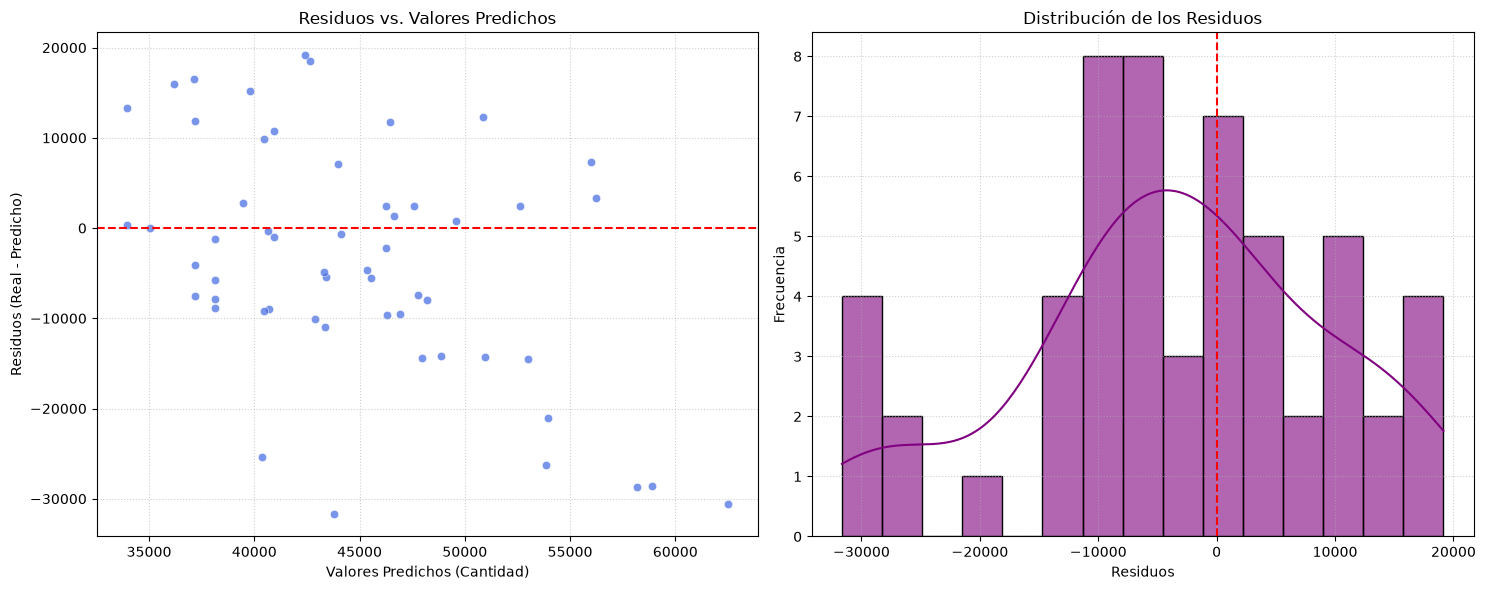

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular los residuos del mejor modelo (Random Forest Optimizado)
residuos_rf = y_test - y_pred_best_rf

# Crear la figura para los gráficos de residuos
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Gráfico de Residuos vs Valores Predichos
sns.scatterplot(x=y_pred_best_rf, y=residuos_rf, ax=axes[0], color='royalblue', alpha=0.7)
axes[0].axhline(y=0, color='r', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuos vs. Valores Predichos')
axes[0].set_xlabel('Valores Predichos (Cantidad)')
axes[0].set_ylabel('Residuos (Real - Predicho)')
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Histograma de la distribución de los residuos
sns.histplot(residuos_rf, kde=True, ax=axes[1], color='purple', bins=15, alpha=0.6)
axes[1].axvline(x=0, color='r', linestyle='--', linewidth=1.5)
axes[1].set_title('Distribución de los Residuos')
axes[1].set_xlabel('Residuos')
axes[1].set_ylabel('Frecuencia')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Exportación del Modelo y Script de Inferencia

In [11]:
import joblib
import os

# Definir la ruta de guardado para el modelo
modelo_path = '../output/modelo_rf_optimizado.pkl'

# Crear la carpeta de salida si no existe
os.makedirs(os.path.dirname(modelo_path), exist_ok=True)

# Exportar el modelo optimizado
joblib.dump(best_rf, modelo_path)
print(f"Modelo guardado con éxito en: {modelo_path}")

Modelo guardado con éxito en: ../output/modelo_rf_optimizado.pkl


A continuación, creamos el script de inferencia `inferencia.py`. Este script puede ser ejecutado de forma autónoma. Automatiza la carga del modelo entrenado, la preparación y transformación de un DataFrame de entrada (creando lags, medias móviles y variables de calendario) y la generación de predicciones.

In [12]:
script_contenido = """
import pandas as pd
import joblib
import sys

def preparar_datos_inferencia(df_nuevo):
    df = df_nuevo.copy()
    df['fecha'] = pd.to_datetime(df['fecha'])
    df.set_index('fecha', inplace=True)
    df.sort_index(inplace=True)

    # Para inferencia, si hay valores nulos generados por shift/rolling,
    # podemos eliminarlos o rellenarlos para evitar errores en el modelo.
    df.dropna(inplace=True)

    features = [
        'media', 'precipitacion',
    ]

    return df[features], df

def predecir(csv_path, modelo_path):
    # Cargar datos nuevos
    print(f"Cargando datos desde: {csv_path}")
    df_nuevo = pd.read_csv(csv_path)

    # Preparar características
    X, df_procesado = preparar_datos_inferencia(df_nuevo)

    if X.empty:
        print("Error: No hay suficientes datos para generar los lags y medias móviles (se requieren al menos 8 registros).")
        return

    # Cargar modelo
    print(f"Cargando modelo desde: {modelo_path}")
    modelo = joblib.load(modelo_path)

    # Realizar predicciones
    predicciones = modelo.predict(X)

    # Integrar predicciones en el set de datos final
    df_procesado['prediccion_cantidad'] = predicciones

    # Guardar o mostrar resultados
    output_path = csv_path.replace('.csv', '_predicciones.csv')
    df_procesado.to_csv(output_path)
    print(f"Predicciones finalizadas. Resultados guardados en: {output_path}")
    print(df_procesado[['cantidad', 'prediccion_cantidad']].head())

if __name__ == '__main__':
    # Ejemplo de uso: python inferencia.py <ruta_csv_nuevos_datos> <ruta_modelo_pkl>
    if len(sys.argv) > 2:
        csv_input = sys.argv[1]
        model_input = sys.argv[2]
    else:
        # Rutas por defecto
        csv_input = '../output/df_final.csv'
        model_input = '../output/modelo_rf_optimizado.pkl'

    predecir(csv_input, model_input)
"""

# Escribir el script a un archivo físico
with open('../output/inferencia.py', 'w') as f:
    f.write(script_contenido.strip())

print("Script de inferencia guardado con éxito en: /output/inferencia.py")

Script de inferencia guardado con éxito en: /output/inferencia.py
